In [68]:
import numpy as np
from scipy.interpolate import interp1d
from PIL import Image
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from scipy.interpolate import interp1d

In [69]:
def read_im(file):
    """Ensure image in the [0, 1] float format instead of [0, 255] integer."""

    im = plt.imread(file)

    if im.dtype == np.uint8:
        # Convert from [0, 255] uint8 to [0.0, 1.0] float64
        return np.clip(im.astype(np.float64) / 255.0, 0, 1)
    elif im.dtype in [np.float32, np.float64]:
        return np.clip(im, 0.0, 1.0).astype(np.float64)
    else:
        raise Exception("unknown file type")

In [70]:
# images from the paper
source = read_im('scotland_house.png')
target = read_im('scotland_plain.png')

# test images from internet
my_source = read_im('adip-im1.jpg')
my_target = read_im('adip-im2.jpg') 

# test 2 from internet 
my_source2 = read_im('sceneorange.jpeg')
my_target2 = read_im('scenepink.jpeg')

# test  3 from internet 
my_source3 = read_im('img_3.jpg')
my_target3 = read_im('adip_3_roze.jpg')

In [71]:
# IDT Color Transfer – Assignment Version
# Based on Pitié et al. (2007)

def compute_rotation_matrix(dim=3):
    """Generates a random orthonormal rotation matrix."""
    Q, _ = np.linalg.qr(np.random.randn(dim, dim))
    return Q

def match_1d_cdf(source, target):
    """1D histogram matching via inverse CDF."""
    s_sorted = np.sort(source)
    t_sorted = np.sort(target)
    # Normalized cumulative indices (CDF)
    s_cdf = np.linspace(0, 1, len(s_sorted))
    t_cdf = np.linspace(0, 1, len(t_sorted))

    # Interpolated inverse CDF of target
    inv_cdf = interp1d(t_cdf, t_sorted, bounds_error=False, fill_value=(t_sorted[0], t_sorted[-1]))

    # Map source to percentile and apply inverse target CDF
    source_ranks = rankdata(source, method='average') / len(source)
    return inv_cdf(source_ranks)

def iterative_distribution_transfer(source, target, iterations=10):
    """
    Perform iterative distribution transfer (IDT) to match the color distribution
    of the source image to that of the target.
    """
    u = source.copy()
    for _ in range(iterations):
        R = compute_rotation_matrix(u.shape[1])
        u_rot = u @ R.T
        v_rot = target @ R.T
        for i in range(u.shape[1]):
            u_rot[:, i] = match_1d_cdf(u_rot[:, i], v_rot[:, i])
        u = u_rot @ R  # Transform back
    return u

# apply use
def apply_color_transfer(source_img, target_img, iterations=10):
    """Apply IDT color transfer on two images."""
    src_flat = source_img.reshape(-1, 3)
    tgt_flat = target_img.reshape(-1, 3)
    src_transferred = iterative_distribution_transfer(src_flat, tgt_flat, iterations)
    return src_transferred.reshape(source_img.shape)




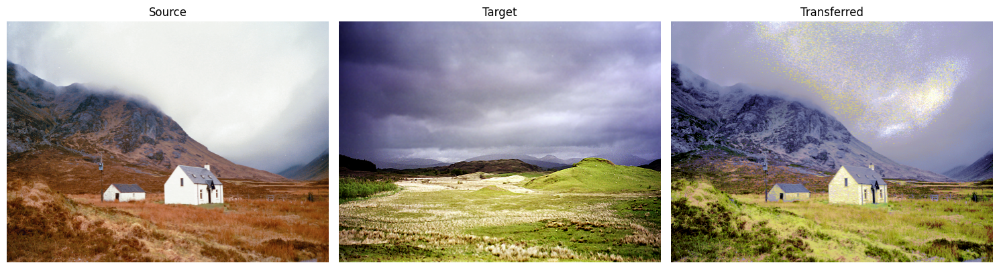

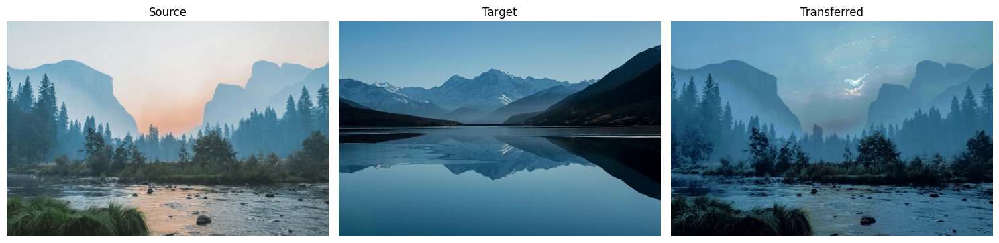

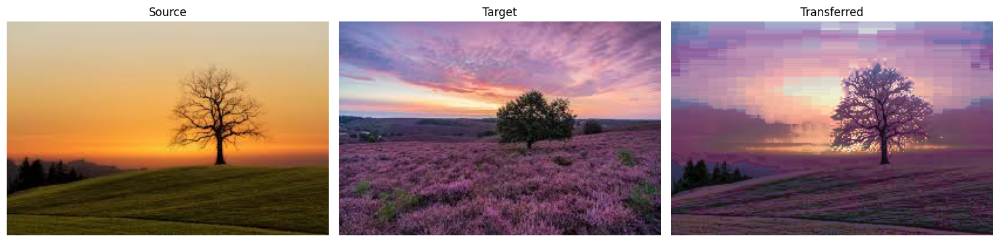

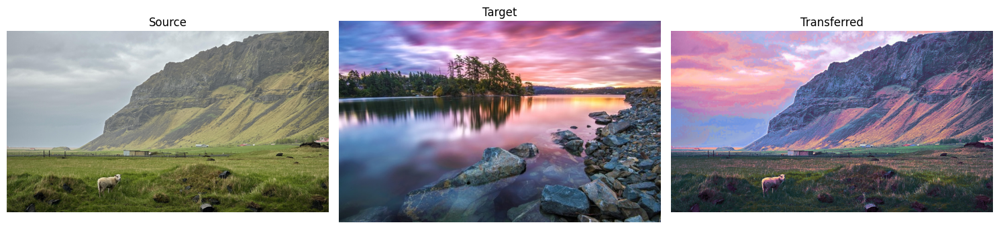

In [72]:
import matplotlib.pyplot as plt
import numpy as np

# color transfer example from paper
result = apply_color_transfer(source, target, iterations=10)
plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(zip([source, target, result], ["Source", "Target", "Transferred"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))  # Already normalized
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

# color transfer internet1 (semi zelfde content en pallete)
result2 = apply_color_transfer(my_source, my_target, iterations=10)
plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(zip([my_source, my_target, result2], ["Source", "Target", "Transferred"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))  # Already normalized
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

# color transfer internet 2 (zelfde content, anders pallete)
result3 = apply_color_transfer(my_source2, my_target2, iterations=10)
plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(zip([my_source2, my_target2, result3], ["Source", "Target", "Transferred"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))  # Already normalized
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

# color transfer internet 3 (andere content, anders pallete)
result4 = apply_color_transfer(my_source3, my_target3, iterations=10)
plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(zip([my_source3, my_target3, result4], ["Source", "Target", "Transferred"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))  # Already normalized
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()



In [73]:
from scipy.stats import gaussian_kde, entropy
import numpy as np
import matplotlib.pyplot as plt

# --- IDT Algorithm with Trajectory Recording ---
def run_idt(source, target, num_iters=20, record_intermediate=True):
    u = source.copy()
    trajectory = [u.copy()] if record_intermediate else None

    for _ in range(num_iters):
        R = compute_rotation_matrix(u.shape[1])
        u_rot = u @ R.T
        v_rot = target @ R.T
        for i in range(u.shape[1]):
            u_rot[:, i] = match_1d_cdf(u_rot[:, i], v_rot[:, i])
        u = u_rot @ R
        if record_intermediate:
            trajectory.append(u.copy())

    return u, trajectory

# --- Updated Visualization Function ---
def plot_idt_pdf_real(source_img, target_img, title_suffix="", sample_size=1000, iterations=20, channels=(0, 1)):
    """
    Matches the visual style of Pitié et al. (2007).
    Works with two selected color channels from real images.
    """
    # Flatten and sample
    src_flat = source_img.reshape(-1, 3)
    tgt_flat = target_img.reshape(-1, 3)

    n = min(len(src_flat), len(tgt_flat), sample_size)
    src_idx = np.random.choice(len(src_flat), n, replace=False)
    tgt_idx = np.random.choice(len(tgt_flat), n, replace=False)
    src_flat = src_flat[src_idx]
    tgt_flat = tgt_flat[tgt_idx]


    # Use only 2 channels and scale to 0–255
    src = src_flat[:, list(channels)] * 255
    tgt = tgt_flat[:, list(channels)] * 255

    # Run IDT
    _, traj = run_idt(src, tgt, num_iters=iterations, record_intermediate=True)

    # Grid for KDE
    padding = 15
    x, y = np.meshgrid(np.linspace(-padding, 255 + padding, 100), np.linspace(-padding, 255 + padding, 100))
    grid_points = np.vstack([x.ravel(), y.ravel()])
    kde_tgt = gaussian_kde(tgt.T)(grid_points)

    # KL divergence
    kl_values = []
    for step in traj:
        kde_src = gaussian_kde(step.T)(grid_points)
        p = kde_src / np.sum(kde_src)
        q = kde_tgt / np.sum(kde_tgt)
        kl = 0.5 * (entropy(p, q) + entropy(q, p))
        kl_values.append(kl)

    # Plot
    fig, axs = plt.subplots(3, 3, figsize=(12, 12))
    steps = [tgt, traj[0], traj[1], traj[2], traj[3], traj[4], traj[6], traj[-1]]
    titles = ["Target", "Original", "iteration 1", "iteration 2", "iteration 3", "iteration 4", "iteration 6", f"iteration {len(traj)-1}"]

    for ax, data, title in zip(axs.flat[:8], steps, titles):
        kde = gaussian_kde(data.T)
        z = kde(np.vstack([x.ravel(), y.ravel()])).reshape(x.shape)
        ax.contour(x, y, z, levels=10, cmap="cool")
        ax.set_xlim(-padding, 255 + padding)
        ax.set_ylim(-padding, 255 + padding)
        ax.set_xticks([50, 100, 150, 200, 250])
        ax.set_yticks([50, 100, 150, 200, 250])
        ax.set_aspect('equal')
        ax.set_title(title, fontsize=10)
        ax.tick_params(labelsize=8)

    # KL plot
    axs.flat[8].plot(range(len(kl_values)), kl_values, 'b-')
    axs.flat[8].set_title("KL measure", fontsize=10)
    axs.flat[8].set_xlabel("iteration", fontsize=9)
    axs.flat[8].set_ylabel("KL", fontsize=9)
    axs.flat[8].set_xlim(0, iterations)
    axs.flat[8].tick_params(labelsize=8)

    plt.suptitle(f" IDT Visualization {title_suffix}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


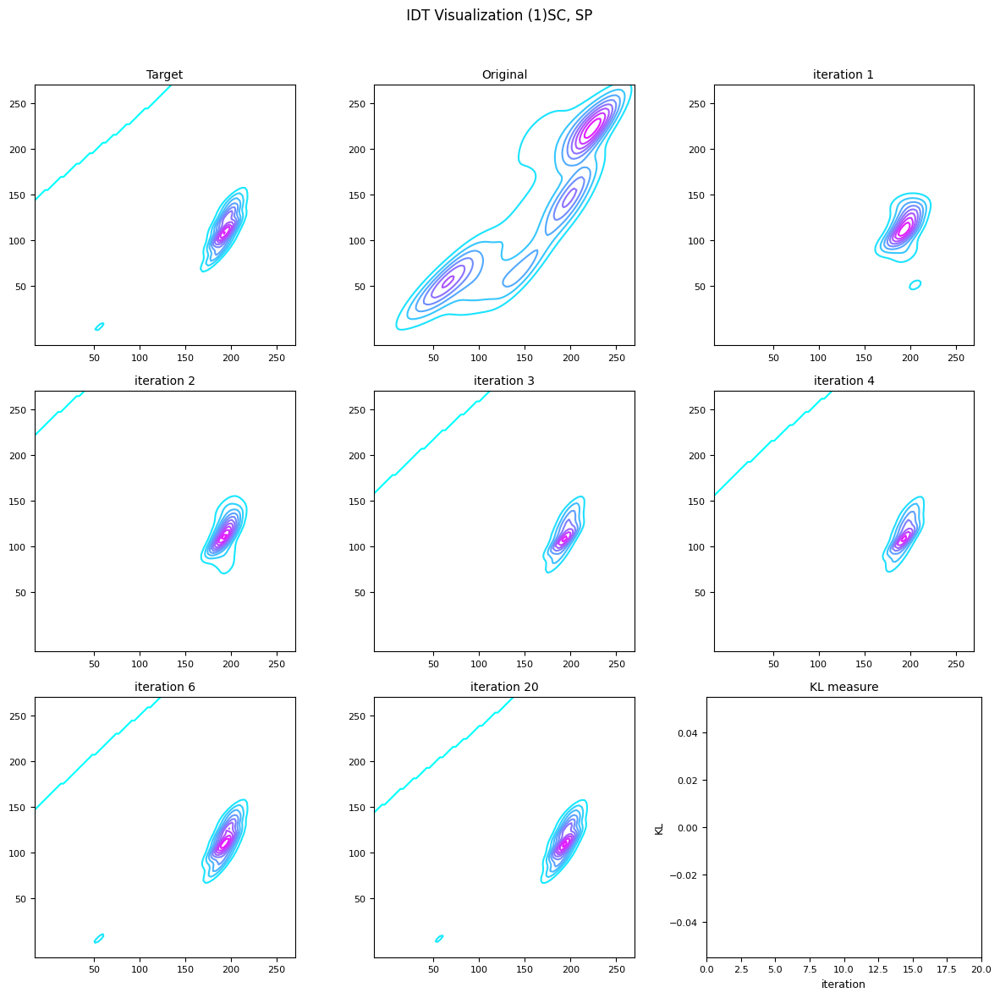

In [74]:
# Step 1: Flatten and equalize
src_flat = my_source.reshape(-1, 3)
tgt_flat = my_target.reshape(-1, 3)
min_len = min(len(src_flat), len(tgt_flat))
src_flat = src_flat[:min_len]
tgt_flat = tgt_flat[:min_len]

# Step 2: Fake reshape back to image (to match function input)
fake_height = min_len // 500  # pick a reasonable width
src_img = src_flat[:fake_height * 500].reshape(fake_height, 500, 3)
tgt_img = tgt_flat[:fake_height * 500].reshape(fake_height, 500, 3)

# Step 3: Run the function
plot_idt_pdf_real(src_img, tgt_img, title_suffix="(1)SC, SP", channels=(2, 0))


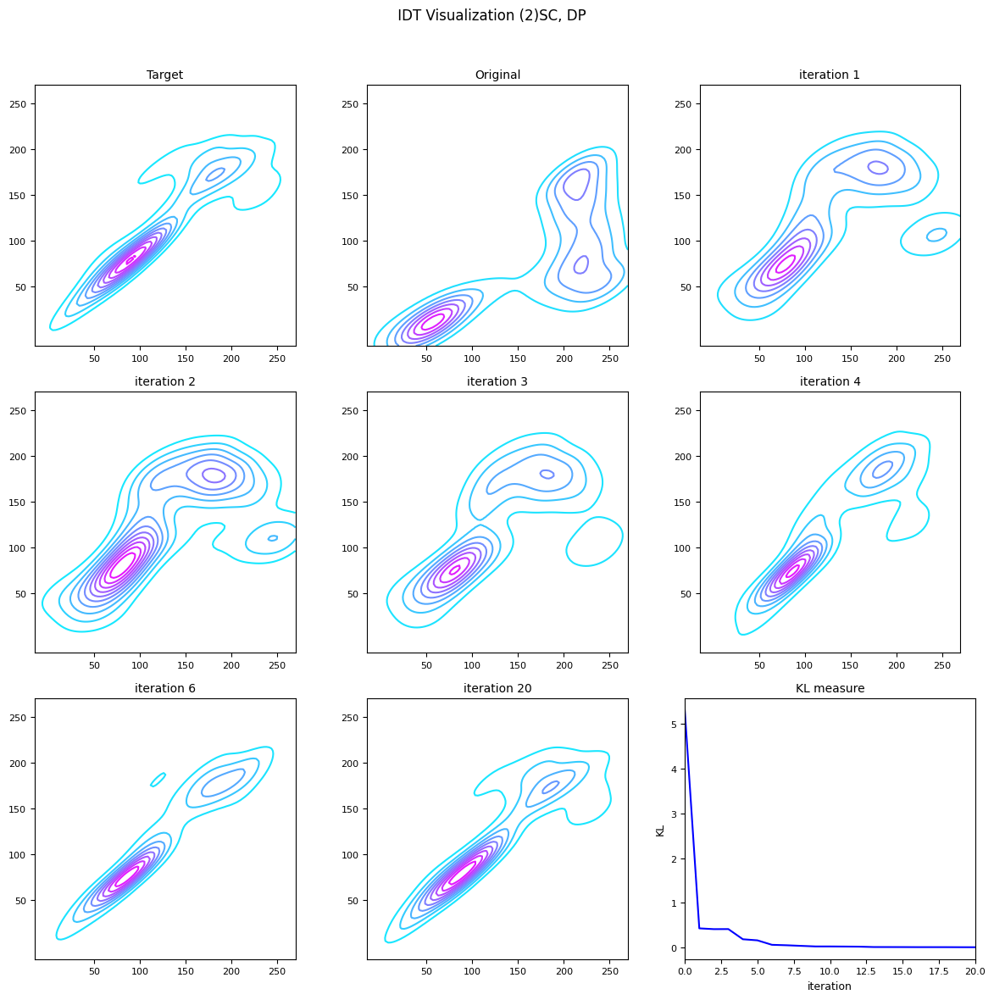

In [75]:
plot_idt_pdf_real(my_source2, my_target2, title_suffix="(2)SC, DP", channels=(0, 2))

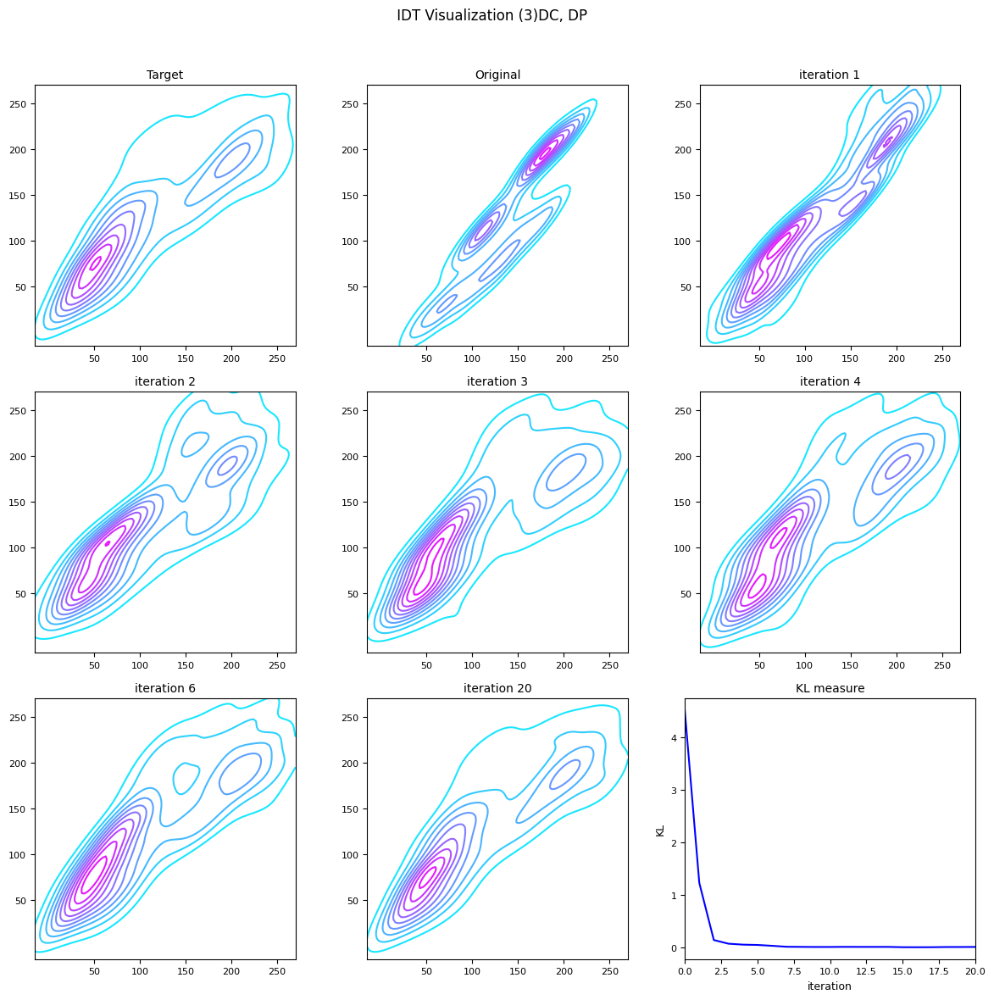

In [76]:
plot_idt_pdf_real(my_source3, my_target3, title_suffix="(3)DC, DP", channels=(0, 2))

In [85]:
from scipy.stats import gaussian_kde, entropy
import numpy as np
import matplotlib.pyplot as plt

def plot_idt_pdf_real(source_img, target_img, title_suffix="", sample_size=1000, iterations=20, channels=(0, 1)):
    # Flatten and sample
    src_flat = source_img.reshape(-1, 3)
    tgt_flat = target_img.reshape(-1, 3)

    n = min(len(src_flat), len(tgt_flat), sample_size)
    src_idx = np.random.choice(len(src_flat), n, replace=False)
    tgt_idx = np.random.choice(len(tgt_flat), n, replace=False)
    src_flat = src_flat[src_idx]
    tgt_flat = tgt_flat[tgt_idx]

    # Use only 2 channels and scale to 0–255
    src = src_flat[:, list(channels)] * 255
    tgt = tgt_flat[:, list(channels)] * 255

    # Run IDT
    _, traj = run_idt(src, tgt, num_iters=iterations, record_intermediate=True)

    # Grid for KDE
    padding = 15
    x, y = np.meshgrid(np.linspace(-padding, 255 + padding, 100), np.linspace(-padding, 255 + padding, 100))
    grid_points = np.vstack([x.ravel(), y.ravel()])
    
    try:
        kde_tgt = gaussian_kde(tgt.T)(grid_points)
    except Exception as e:
        print("Target KDE failed:", e)
        kde_tgt = np.ones_like(grid_points[0])  # prevent crash

    # KL divergence
    kl_values = []
    eps = 1e-10

    for step in traj:
        try:
            kde_src = gaussian_kde(step.T)(grid_points)
            p = kde_src / (np.sum(kde_src) + eps)
            q = kde_tgt / (np.sum(kde_tgt) + eps)
            p = np.clip(p, eps, 1)
            q = np.clip(q, eps, 1)
            kl = 0.5 * (entropy(p, q) + entropy(q, p))
        except Exception as e:
            print(f"KL failed at step {len(kl_values)}:", e)
            kl = np.nan  # or some fallback
        kl_values.append(kl)

    # Replace NaNs with zero or interpolate
    kl_values = np.nan_to_num(kl_values, nan=0.0)

    # Plot
    fig, axs = plt.subplots(3, 3, figsize=(12, 12))
    steps = [tgt, traj[0], traj[1], traj[2], traj[3], traj[4], traj[6], traj[-1]]
    titles = ["Target", "Original", "iteration 1", "iteration 2", "iteration 3", "iteration 4", "iteration 6", f"iteration {len(traj)-1}"]

    

    for ax, data, title in zip(axs.flat[:8], steps, titles):
        try:
            kde = gaussian_kde(data.T)
            z = kde(np.vstack([x.ravel(), y.ravel()])).reshape(x.shape)
            ax.contour(x, y, z, levels=10, cmap="cool")
        except Exception as e:
            print(f"Plotting KDE failed at {title}:", e)
            ax.text(0.5, 0.5, 'KDE Failed', ha='center')
        ax.set_xlim(-padding, 255 + padding)
        ax.set_ylim(-padding, 255 + padding)
        ax.set_xticks([50, 100, 150, 200, 250])
        ax.set_yticks([50, 100, 150, 200, 250])
        ax.set_aspect('equal')
        ax.set_title(title, fontsize=10)
        ax.tick_params(labelsize=8)

    # KL plot
    axs.flat[8].plot(range(len(kl_values)), kl_values, 'b-')
    axs.flat[8].set_title("KL measure", fontsize=10)
    axs.flat[8].set_xlabel("iteration", fontsize=9)
    axs.flat[8].set_ylabel("KL", fontsize=9)
    axs.flat[8].set_xlim(0, iterations)
    axs.flat[8].tick_params(labelsize=8)

    plt.suptitle(f"IDT Visualization {title_suffix}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


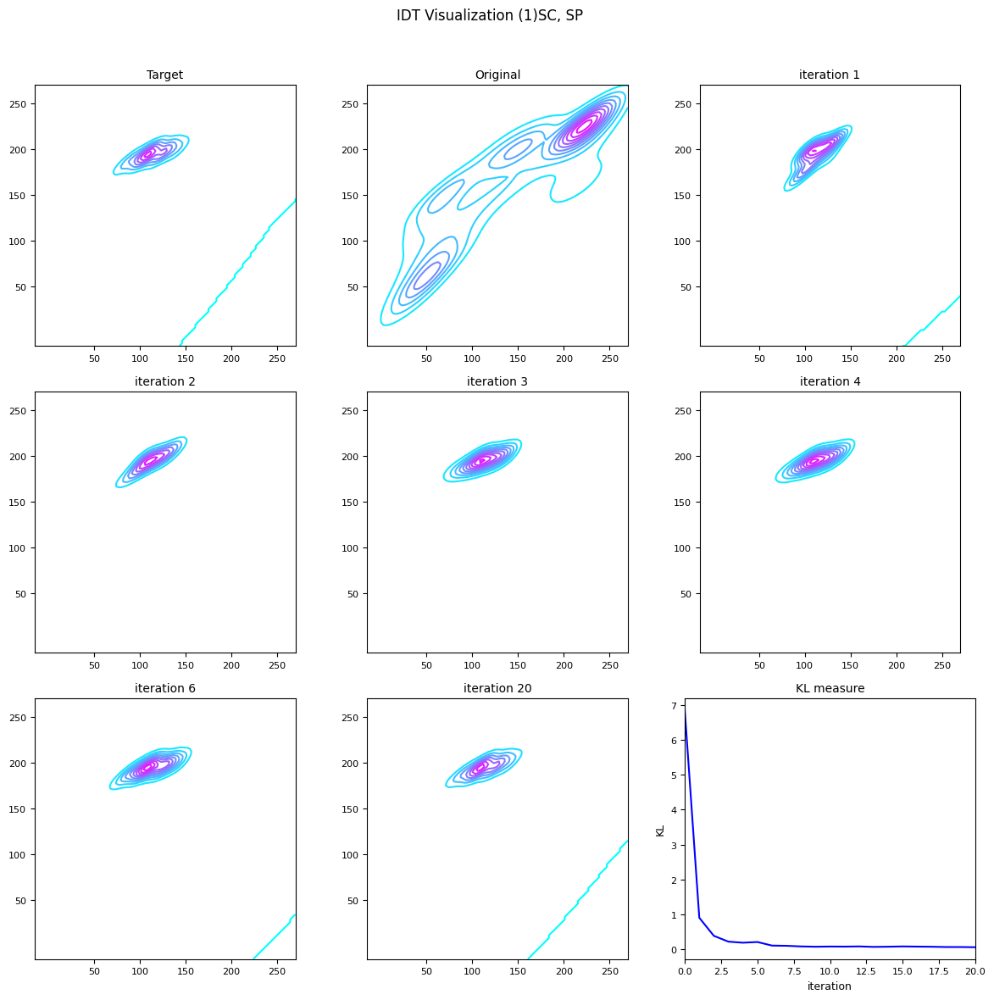

In [86]:
plot_idt_pdf_real(src_img, tgt_img, title_suffix="(1)SC, SP", channels=(0, 2))  #


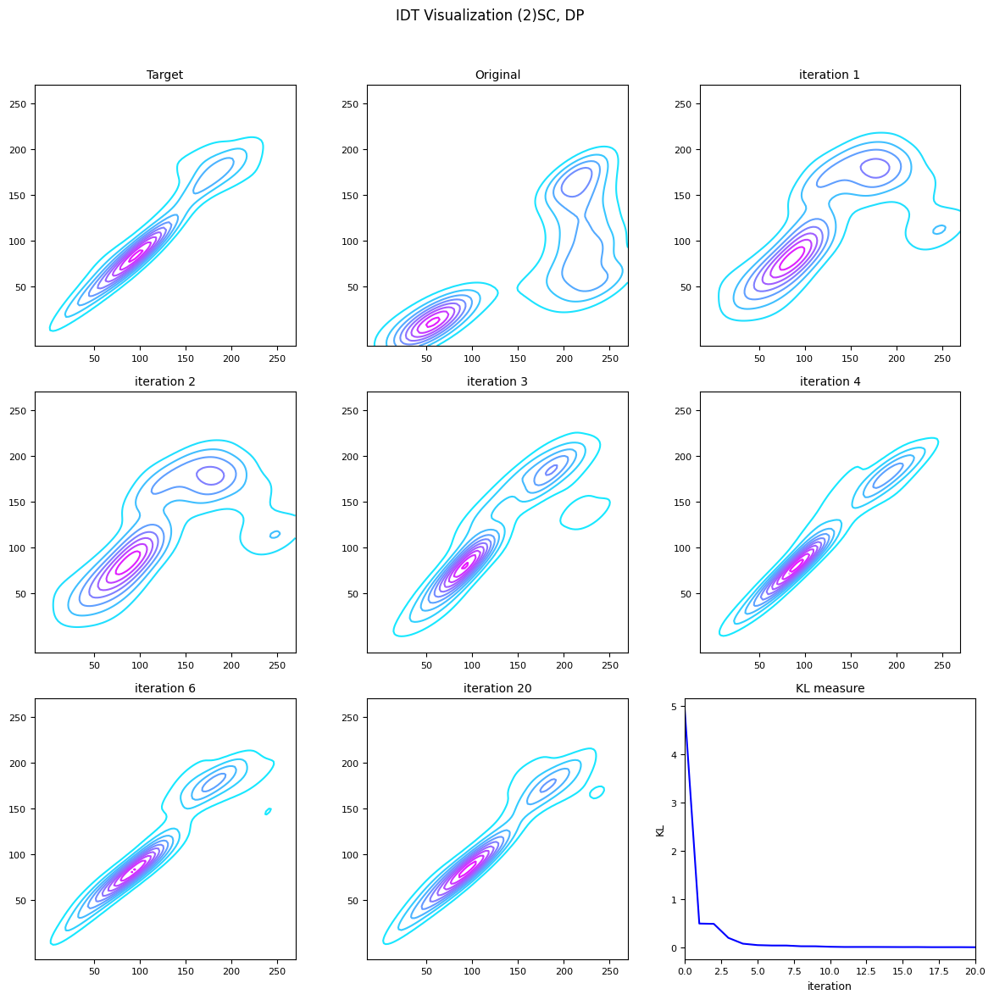

In [87]:
plot_idt_pdf_real(my_source2, my_target2, title_suffix="(2)SC, DP", channels=(0, 2))

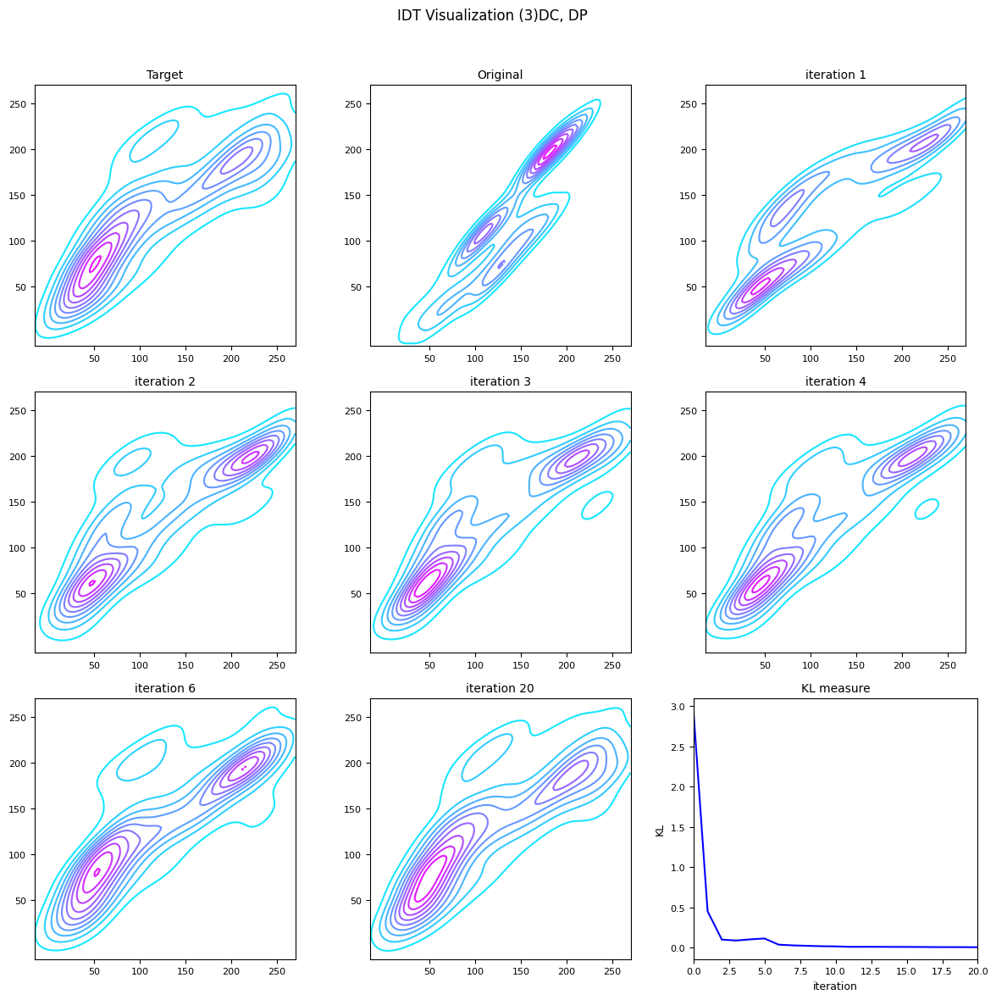

In [88]:
plot_idt_pdf_real(my_source3, my_target3, title_suffix="(3)DC, DP", channels=(0, 2))

In [42]:
# re-graining prep

def shift(img):
    """Return four shifted copies of the array in order L, R, U, D.
    Where L, R, U, D are defined as
        L(x, y) = img(x-1, y)
        R(x, y) = img(x+1, y)
        U(x, y) = img(x, y+1)
        D(x, y) = img(x, y-1).
    Because of the intended use in the poisson regraining function,
    the L/R/U/D most row is doubled as to transform interpolation into
    using that only known value and taking derivative 0 at the edge.
    """
    L = np.roll(img, -1, axis=1)
    L[:, 0] = img[:, 0]
    R = np.roll(img, 1, axis=1)
    R[:, -1] = img[:, -1]
    D = np.roll(img, -1, axis=0)
    D[-1, :] = img[-1,:]
    U = np.roll(img, 1, axis=0)
    U[0, :] = img[0, :]

    return L, R, U, D


In [43]:
shift(np.array([[1, 2], [3, 4]]))

(array([[1, 1],
        [3, 3]]),
 array([[2, 2],
        [4, 4]]),
 array([[1, 2],
        [1, 2]]),
 array([[3, 4],
        [3, 4]]))

In [45]:
# re-graining

def poisson_regrain(original, transferred, initial_guess="transferred", num_iters=100, tolerance=1e-3):
    
    J = np.zeros_like(original, dtype=np.float64)

    for c in range(3):
        I = original[:, :, c]
        tI = transferred[:, :, c]

        # Compute gradient
        gy, gx = np.gradient(I.astype('float64'))
        # factor 255 to reproduce the 0 to 255 scaling of the paper
        grad_I = np.sqrt(gx**2 + gy**2)

        # original gradient matching
        phi = 30 / (1 + 10 * grad_I)
        # transferred colour matching
        psi = np.where(grad_I < 5, grad_I / 5, 1)

        # Shifted phi
        phi_left, phi_right, phi_up, phi_down = shift(phi)

        # Coefficients
        a1 = -(phi_down + phi) / 2
        a2 = -(phi_up + phi) / 2
        a3 = -(phi_left + phi) / 2
        a4 = -(phi_right + phi) / 2
        a5 = 0.5 * (4 * phi + phi_up + phi_down + phi_left + phi_right) + psi

        # Shifted I
        I_left, I_right, I_up, I_down = shift(I)

        a6 = - 0.5 * ((phi + phi_up) * (I_up - I) +
                    (phi + phi_down) * (I_down - I) +
                    (phi + phi_left) * (I_left - I) +
                    (phi + phi_right) * (I_right - I)) + psi * tI

        # Initial guess
        if initial_guess == "transferred":
            J_old = tI.copy()
        elif initial_guess == "zeros":
            J_old = np.zeros_like(I)
        elif initial_guess == "original":
            J_old = I.copy()
        else:
            raise Exception("invalid initial guess (transferred, zeros, original)")

        for i in range(num_iters):

            J_left, J_right, J_up, J_down = shift(J_old)

            J_new = (1 / a5) * (
                a6
                - a1 * J_down
                - a2 * J_up
                - a3 * J_left
                - a4 * J_right
            )

            # Neumann BCs to preserve I's gradient at edges
            J_new[0, 1:-1] = J_new[1, 1:-1] + (I[0, 1:-1] - I[1, 1:-1])
            J_new[-1, 1:-1] = J_new[-2, 1:-1] + (I[-1, 1:-1] - I[-2, 1:-1])
            J_new[1:-1, 0] = J_new[1:-1, 1] + (I[1:-1, 0] - I[1:-1, 1])
            J_new[1:-1, -1] = J_new[1:-1, -2] + (I[1:-1, -1] - I[1:-1, -2])

            # check if the image is changing from iteration to iteraction
            if np.sum( (J_old - J_new)**2 ) < tolerance:
                print(f"tolerance reached after {i} iterations")
                break

            J_old = J_new

        J[:, :, c] = J_new

    return J


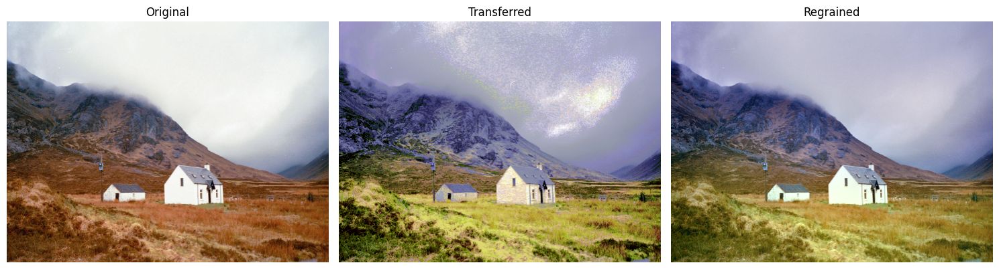

In [46]:
# apply re-graining

regrained = poisson_regrain(source, result, initial_guess="transferred", num_iters=2000)

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(
    zip([source, result, regrained], ["Original", "Transferred", "Regrained"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()




tolerance reached after 1797 iterations


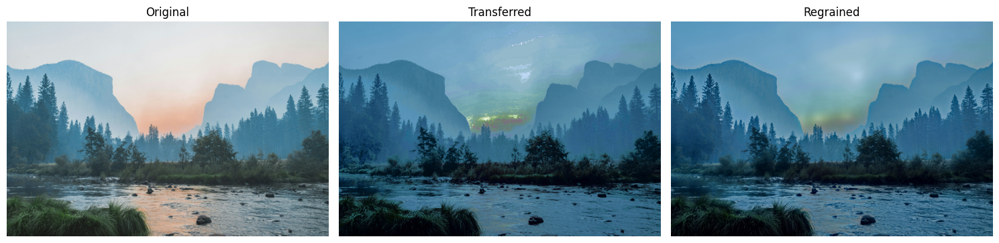

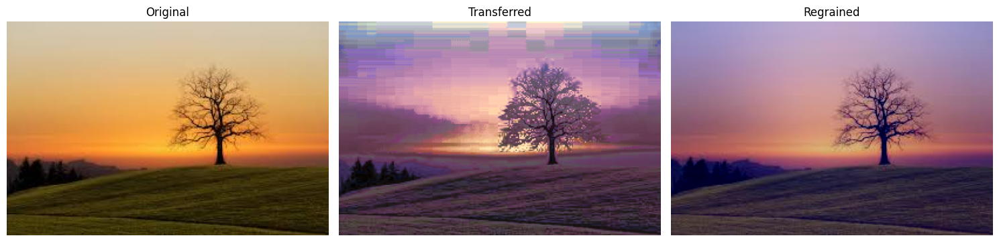

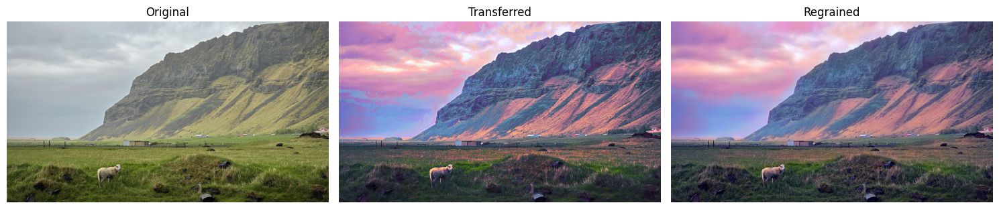

In [47]:
my_regrained = poisson_regrain(my_source, result2, initial_guess="transferred", num_iters=2000)
my_regrained2 = poisson_regrain(my_source2, result3, initial_guess="transferred", num_iters=2000)
my_regrained3 = poisson_regrain(my_source3, result4, initial_guess="transferred", num_iters=2000)

plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(
    zip([my_source, result2, my_regrained], ["Original", "Transferred", "Regrained"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(
    zip([my_source2, result3, my_regrained2], ["Original", "Transferred", "Regrained"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate(
    zip([my_source3, result4, my_regrained3], ["Original", "Transferred", "Regrained"]), 1):
    plt.subplot(1, 3, i)
    plt.imshow(np.clip(img, 0, 1))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()